In [1]:

# Bank Transaction Fraud Analysis
# Step 1: Import the libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

print("Libraries imported successfully!")


Libraries imported successfully!


In [4]:
# Step 2: Load the dataset
# Note: Please upload 'bank_fraud.csv' using the folder icon on the left sidebar first.

df = pd.read_csv("bank_fraud.csv")

In [5]:
# Check the dataset size
print("Dataset dimensions:", df.shape)

Dataset dimensions: (20450, 26)


In [6]:
# Preview the first five rows
display(df.head())

,transaction_id,customer_id,transaction_date,transaction_time,hour_of_day,is_weekend,is_night_transaction,country,city,merchant_category,payment_method,device_type,customer_age,credit_score,account_age_years,account_balance,transaction_amount,num_prev_transactions,transaction_freq_monthly,distance_from_home_km,time_since_last_txn_hrs,is_international,failed_attempts,pin_changed_recently,is_fraud,fraud_type
0,TXN0000000001,CUST00121959,2023-08-17,21:13:00,21,0,0,USA,London,Grocery,Bank Transfer,POS Terminal,18,695,7.20,369.36,39.49,157,23,52.70,10.20,0.00,0.00,0.00,0.00,NaN
1,TXN0000000002,CUST00146868,2024-02-06,05:16:00,5,0,1,UK,New York,Healthcare,Cheque,Desktop,30,600,8.60,"2,681.99",153.71,153,23,0.90,12.47,0.00,0.00,0.00,0.00,NaN
2,TXN0000000003,CUST00131933,2024-06-28,12:15:00,12,0,0,Canada,Delhi,Grocery,Crypto,Mobile,20,711,10.80,"44,590.64",118.20,161,20,9.20,0.08,0.00,1.00,0.00,0.00,NaN
3,TXN0000000004,CUST00103695,2023-03-16,02:53:00,2,0,1,France,Tokyo,Utilities,Debit Card,Mobile,29,711,7.30,"1,213.37",49.50,160,25,14.80,17.94,1.00,0.00,1.00,1.00,Synthetic Identity
4,TXN0000000005,CUST00119880,2024-07-12,12:39:00,12,0,0,Canada,Melbourne,Clothing,Debit Card,Desktop,49,751,11.80,"34,615.01",30.74,134,18,38.90,2.16,0.00,0.00,0.00,0.00,NaN


In [7]:
# Check column names
print("\nColumn names:")
print(df.columns.tolist())


Column names:
['transaction_id', 'customer_id', 'transaction_date', 'transaction_time', 'hour_of_day', 'is_weekend', 'is_night_transaction', 'country', 'city', 'merchant_category', 'payment_method', 'device_type', 'customer_age', 'credit_score', 'account_age_years', 'account_balance', 'transaction_amount', 'num_prev_transactions', 'transaction_freq_monthly', 'distance_from_home_km', 'time_since_last_txn_hrs', 'is_international', 'failed_attempts', 'pin_changed_recently', 'is_fraud', 'fraud_type']


In [8]:
# Check data types and missing values
print("\nDataset information:")
df.info()


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20450 entries, 0 to 20449
Data columns (total 26 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   transaction_id            20450 non-null  object 
 1   customer_id               20450 non-null  object 
 2   transaction_date          20450 non-null  object 
 3   transaction_time          20450 non-null  object 
 4   hour_of_day               20450 non-null  int64  
 5   is_weekend                20450 non-null  int64  
 6   is_night_transaction      20450 non-null  int64  
 7   country                   20450 non-null  object 
 8   city                      20450 non-null  object 
 9   merchant_category         20450 non-null  object 
 10  payment_method            20450 non-null  object 
 11  device_type               20450 non-null  object 
 12  customer_age              20450 non-null  int64  
 13  credit_score              20450 non-nul

In [9]:
# Step 3: Check missing values

print("Missing values in each column:")
display(df.isnull().sum().sort_values(ascending=False))

print("\nMissing values percentage:")
display((df.isnull().mean() * 100).round(2))

Missing values in each column:


,0
fraud_type,19328
pin_changed_recently,1
failed_attempts,1
is_international,1
is_fraud,1
hour_of_day,0
transaction_date,0
transaction_time,0
transaction_id,0
customer_id,0



Missing values percentage:


,0
transaction_id,0.00
customer_id,0.00
transaction_date,0.00
transaction_time,0.00
hour_of_day,0.00
is_weekend,0.00
is_night_transaction,0.00
country,0.00
city,0.00
merchant_category,0.00


In [10]:
# Check duplicate records
print("\nNumber of duplicate rows:", df.duplicated().sum())


Number of duplicate rows: 0


In [11]:
# Step 4: Statistical summary

print("Statistical summary of numerical columns:")
display(df.describe().T)

Statistical summary of numerical columns:


,count,mean,std,min,25%,50%,75%,max
hour_of_day,"20,450.00",11.53,6.93,0.00,5.00,12.00,18.00,23.00
is_weekend,"20,450.00",0.29,0.45,0.00,0.00,0.00,1.00,1.00
is_night_transaction,"20,450.00",0.37,0.48,0.00,0.00,0.00,1.00,1.00
customer_age,"20,450.00",41.64,13.38,18.00,32.00,41.00,51.00,85.00
credit_score,"20,450.00",679.65,78.86,384.00,626.00,679.00,734.00,850.00
account_age_years,"20,450.00",4.93,4.83,0.10,1.50,3.40,6.90,30.00
account_balance,"20,450.00","16,640.66","28,768.80",100.00,"3,573.40","7,979.43","18,325.53","500,000.00"
transaction_amount,"20,450.00",201.46,436.89,1.26,33.10,72.78,181.61,"13,851.98"
num_prev_transactions,"20,450.00",150.02,12.23,105.00,142.00,150.00,158.00,201.00
transaction_freq_monthly,"20,450.00",20.01,4.46,5.00,17.00,20.00,23.00,39.00


In [12]:

# Step 4: Descriptive Statistics

numeric_columns = [
    "customer_age",
    "credit_score",
    "account_age_years",
    "account_balance",
    "transaction_amount",
    "num_prev_transactions",
    "transaction_freq_monthly",
    "distance_from_home_km",
    "time_since_last_txn_hrs",
    "failed_attempts"
]

print("NUMERICAL SUMMARY")
display(df[numeric_columns].describe().T.round(2))

# Overall transaction amount statistics
print("\nTRANSACTION AMOUNT SUMMARY")

print("Total transaction value:",
      round(df["transaction_amount"].sum(), 2))

print("Average transaction amount:",
      round(df["transaction_amount"].mean(), 2))

print("Median transaction amount:",
      round(df["transaction_amount"].median(), 2))

print("Largest transaction:",
      round(df["transaction_amount"].max(), 2))


NUMERICAL SUMMARY


,count,mean,std,min,25%,50%,75%,max
customer_age,"20,450.00",41.64,13.38,18.00,32.00,41.00,51.00,85.00
credit_score,"20,450.00",679.65,78.86,384.00,626.00,679.00,734.00,850.00
account_age_years,"20,450.00",4.93,4.83,0.10,1.50,3.40,6.90,30.00
account_balance,"20,450.00","16,640.66","28,768.80",100.00,"3,573.40","7,979.44","18,325.53","500,000.00"
transaction_amount,"20,450.00",201.46,436.89,1.26,33.10,72.78,181.61,"13,851.98"
num_prev_transactions,"20,450.00",150.02,12.23,105.00,142.00,150.00,158.00,201.00
transaction_freq_monthly,"20,450.00",20.01,4.46,5.00,17.00,20.00,23.00,39.00
distance_from_home_km,"20,450.00",19.86,19.73,0.00,5.70,13.80,27.70,232.50
time_since_last_txn_hrs,"20,450.00",12.09,12.05,0.00,3.47,8.44,16.82,109.56
failed_attempts,"20,449.00",0.38,0.90,0.00,0.00,0.00,0.00,5.00



TRANSACTION AMOUNT SUMMARY
Total transaction value: 4119894.87
Average transaction amount: 201.46
Median transaction amount: 72.78
Largest transaction: 13851.98


In [13]:

# Step 5: Overall Fraud Analysis

# Total number of transactions
total_transactions = len(df)

# Separate legitimate and fraudulent transactions
fraud_counts = df["is_fraud"].value_counts()

total_fraud = (df["is_fraud"] == 1).sum()
total_legitimate = (df["is_fraud"] == 0).sum()

# Calculate percentages
fraud_percentage = (total_fraud / total_transactions) * 100
legitimate_percentage = (total_legitimate / total_transactions) * 100

# Display results
print("OVERALL BANK TRANSACTION ANALYSIS")
print("=" * 40)

print(f"Total transactions: {total_transactions:,}")
print(f"Fraudulent transactions: {total_fraud:,}")
print(f"Legitimate transactions: {total_legitimate:,}")

print(f"\nFraud rate: {fraud_percentage:.2f}%")
print(f"Legitimate transaction rate: {legitimate_percentage:.2f}%")


OVERALL BANK TRANSACTION ANALYSIS
Total transactions: 20,450
Fraudulent transactions: 1,122
Legitimate transactions: 19,327

Fraud rate: 5.49%
Legitimate transaction rate: 94.51%


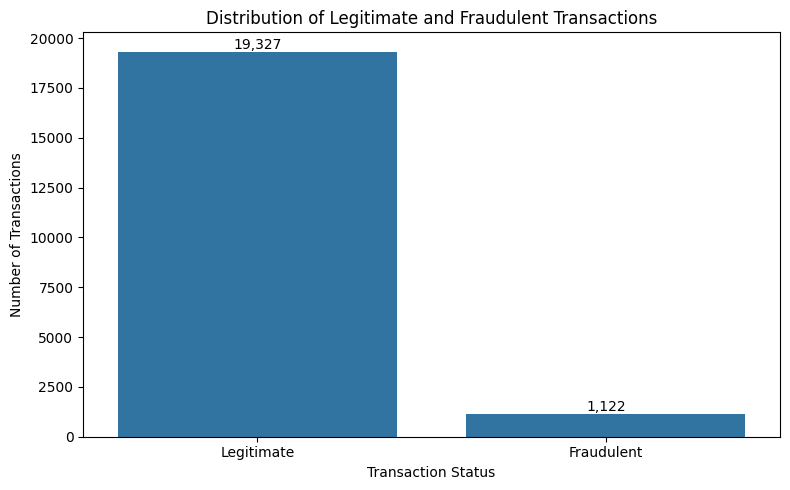

In [14]:

# Step 6: Transaction Distribution

import matplotlib.pyplot as plt
import seaborn as sns

fraud_labels = df["is_fraud"].map({
    0: "Legitimate",
    1: "Fraudulent"
})

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    x=fraud_labels,
    order=["Legitimate", "Fraudulent"]
)

plt.title("Distribution of Legitimate and Fraudulent Transactions")
plt.xlabel("Transaction Status")
plt.ylabel("Number of Transactions")

for bar in ax.patches:
    ax.annotate(
        f"{int(bar.get_height()):,}",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


Fraud Cases by Type


,Fraud Type,Number of Cases
0,Friendly Fraud,208
1,Phishing,190
2,Account Takeover,184
3,Synthetic Identity,183
4,Card Cloning,183
5,Identity Theft,174


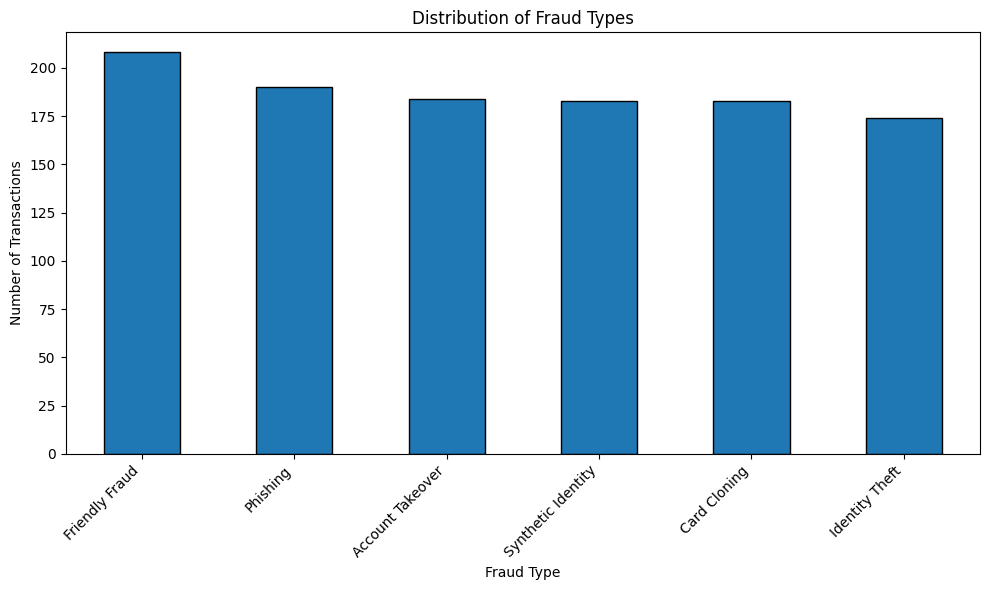

In [15]:

# Step 7: Fraud Type Analysis

fraud_data = df[df["is_fraud"] == 1].copy()

fraud_type_counts = (
    fraud_data["fraud_type"]
    .fillna("Unknown")
    .value_counts()
)

print("Fraud Cases by Type")
display(
    fraud_type_counts.rename_axis("Fraud Type")
    .reset_index(name="Number of Cases")
)

plt.figure(figsize=(10, 6))

fraud_type_counts.plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Distribution of Fraud Types")
plt.xlabel("Fraud Type")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [16]:

# Step 8: Financial Impact Analysis

financial_analysis = df.groupby("is_fraud")["transaction_amount"].agg(
    Transaction_Count="count",
    Total_Transaction_Value="sum",
    Average_Transaction_Amount="mean",
    Median_Transaction_Amount="median",
    Maximum_Transaction_Amount="max"
)

financial_analysis.index = financial_analysis.index.map({
    0: "Legitimate",
    1: "Fraudulent"
})

display(financial_analysis.round(2))


,Transaction_Count,Total_Transaction_Value,Average_Transaction_Amount,Median_Transaction_Amount,Maximum_Transaction_Amount
is_fraud,,,,,
Legitimate,19327,"3,877,994.27",200.65,72.43,"13,851.98"
Fraudulent,1122,"241,791.66",215.50,79.74,"6,486.65"


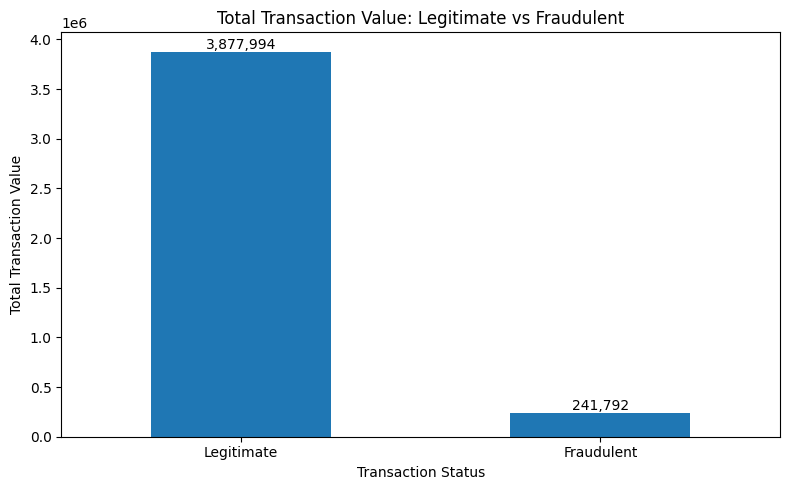

In [17]:

# Step 9: Total Transaction Value by Fraud Status

transaction_totals = df.groupby("is_fraud")["transaction_amount"].sum()
transaction_totals.index = ["Legitimate", "Fraudulent"]

plt.figure(figsize=(8, 5))

ax = transaction_totals.plot(kind="bar")

plt.title("Total Transaction Value: Legitimate vs Fraudulent")
plt.xlabel("Transaction Status")
plt.ylabel("Total Transaction Value")
plt.xticks(rotation=0)

for bar in ax.patches:
    ax.annotate(
        f"{bar.get_height():,.0f}",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


,Number_of_Cases,Total_Amount,Average_Amount,Median_Amount
fraud_type,,,,
Friendly Fraud,208,"52,884.15",254.25,79.73
Card Cloning,183,"48,982.03",267.66,91.68
Account Takeover,184,"36,992.54",201.05,79.04
Identity Theft,174,"36,879.83",211.95,86.51
Synthetic Identity,183,"33,855.80",185.00,69.87
Phishing,190,"32,197.31",169.46,68.85


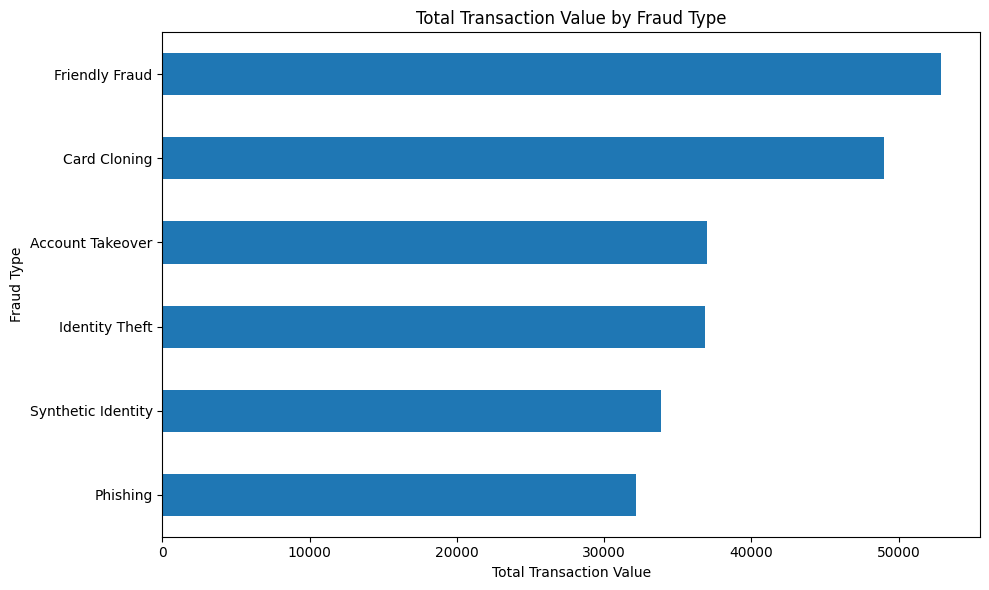

In [18]:

# Step 10: Financial Impact by Fraud Type

fraud_data = df[df["is_fraud"] == 1].copy()

fraud_type_financial = fraud_data.groupby("fraud_type")[
    "transaction_amount"
].agg(
    Number_of_Cases="count",
    Total_Amount="sum",
    Average_Amount="mean",
    Median_Amount="median"
).sort_values("Total_Amount", ascending=False)

display(fraud_type_financial.round(2))

# Visualize total transaction value by fraud type
plt.figure(figsize=(10, 6))

fraud_type_financial["Total_Amount"].sort_values().plot(
    kind="barh"
)

plt.title("Total Transaction Value by Fraud Type")
plt.xlabel("Total Transaction Value")
plt.ylabel("Fraud Type")
plt.tight_layout()
plt.show()


,Total_Transactions,Fraud_Cases,Fraud_Rate_Percent
hour_of_day,,,
0,839,64.00,7.63
1,874,76.00,8.70
2,853,68.00,7.97
3,819,59.00,7.20
4,848,60.00,7.08
5,893,80.00,8.96
6,794,52.00,6.55
7,875,45.00,5.14
8,862,43.00,4.99


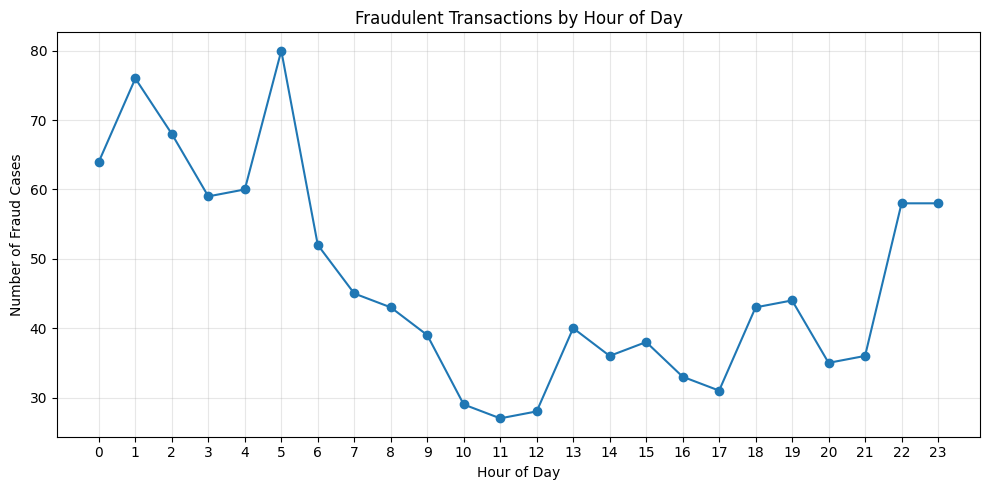

,Total_Transactions,Fraud_Cases,Fraud_Rate,Fraud_Rate_Percent
is_night_transaction,,,,
0,12858,547.00,0.04,4.25
1,7592,575.00,0.08,7.57


In [19]:

# Step 11: Fraud by Time of Day

# Fraud counts by hour
hourly_analysis = df.groupby("hour_of_day").agg(
    Total_Transactions=("is_fraud", "size"),
    Fraud_Cases=("is_fraud", "sum")
)

hourly_analysis["Fraud_Rate_Percent"] = (
    hourly_analysis["Fraud_Cases"]
    / hourly_analysis["Total_Transactions"] * 100
).round(2)

display(hourly_analysis)

# Fraud count by hour
hourly_analysis["Fraud_Cases"].plot(
    kind="line", marker="o", figsize=(10, 5)
)

plt.title("Fraudulent Transactions by Hour of Day")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Fraud Cases")
plt.xticks(range(0, 24))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Compare night transactions
night_analysis = df.groupby("is_night_transaction").agg(
    Total_Transactions=("is_fraud", "size"),
    Fraud_Cases=("is_fraud", "sum"),
    Fraud_Rate=("is_fraud", "mean")
)

night_analysis["Fraud_Rate_Percent"] = (
    night_analysis["Fraud_Rate"] * 100
).round(2)

display(night_analysis)


,Total_Transactions,Fraud_Cases,Fraud_Rate,Fraud_Rate_Percent
is_weekend,,,,
0,14594,776.00,0.05,5.32
1,5856,346.00,0.06,5.91


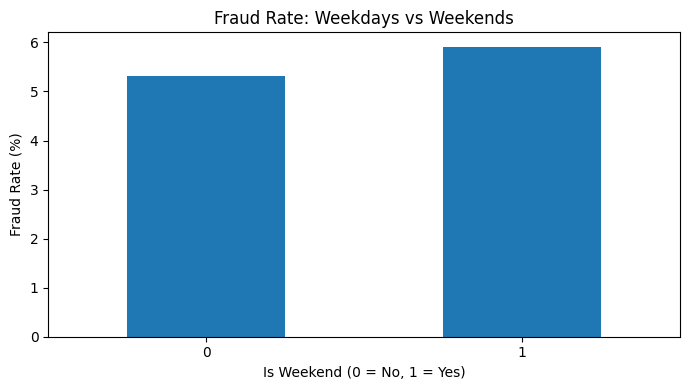

In [20]:

# Step 12: Weekend Analysis

weekend_analysis = df.groupby("is_weekend").agg(
    Total_Transactions=("is_fraud", "size"),
    Fraud_Cases=("is_fraud", "sum"),
    Fraud_Rate=("is_fraud", "mean")
)

weekend_analysis["Fraud_Rate_Percent"] = (
    weekend_analysis["Fraud_Rate"] * 100
).round(2)

display(weekend_analysis)

weekend_analysis["Fraud_Rate_Percent"].plot(
    kind="bar", figsize=(7, 4)
)

plt.title("Fraud Rate: Weekdays vs Weekends")
plt.xlabel("Is Weekend (0 = No, 1 = Yes)")
plt.ylabel("Fraud Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


,Total_Transactions,Fraud_Cases,Fraud_Rate,Fraud_Rate_Percent
payment_method,,,,
Cheque,615,41.00,0.07,6.67
Crypto,1018,66.00,0.06,6.48
Bank Transfer,3085,174.00,0.06,5.64
Credit Card,7046,381.00,0.05,5.41
Debit Card,6190,334.00,0.05,5.40
Mobile Payment,2496,126.00,0.05,5.05


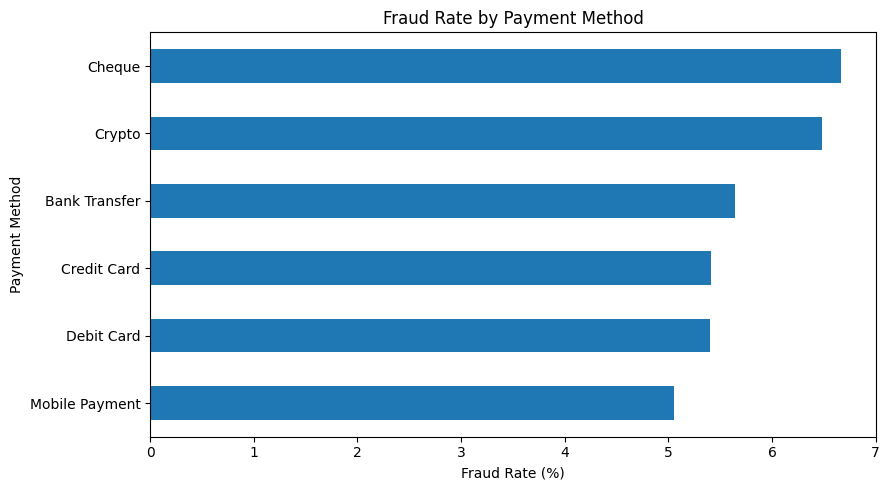

,Total_Transactions,Fraud_Cases,Fraud_Rate,Fraud_Rate_Percent
merchant_category,,,,
Jewelry,1345,117.00,0.09,8.70
Crypto Exchange,1338,110.00,0.08,8.22
ATM Withdrawal,1383,113.00,0.08,8.17
Healthcare,1372,73.00,0.05,5.32
Grocery,1365,72.00,0.05,5.27
Utilities,1380,71.00,0.05,5.15
Online Shopping,1352,68.00,0.05,5.03
Clothing,1386,69.00,0.05,4.98
Fuel,1323,65.00,0.05,4.91


In [21]:

# Step 13: Payment Method Analysis

payment_analysis = df.groupby("payment_method").agg(
    Total_Transactions=("is_fraud", "size"),
    Fraud_Cases=("is_fraud", "sum"),
    Fraud_Rate=("is_fraud", "mean")
)

payment_analysis["Fraud_Rate_Percent"] = (
    payment_analysis["Fraud_Rate"] * 100
).round(2)

display(
    payment_analysis.sort_values(
        "Fraud_Rate_Percent", ascending=False
    )
)

payment_analysis["Fraud_Rate_Percent"].sort_values().plot(
    kind="barh", figsize=(9, 5)
)

plt.title("Fraud Rate by Payment Method")
plt.xlabel("Fraud Rate (%)")
plt.ylabel("Payment Method")
plt.tight_layout()
plt.show()


# Fraud by merchant category
merchant_analysis = df.groupby("merchant_category").agg(
    Total_Transactions=("is_fraud", "size"),
    Fraud_Cases=("is_fraud", "sum"),
    Fraud_Rate=("is_fraud", "mean")
)

merchant_analysis["Fraud_Rate_Percent"] = (
    merchant_analysis["Fraud_Rate"] * 100
).round(2)

display(
    merchant_analysis.sort_values(
        "Fraud_Rate_Percent", ascending=False
    )
)


,Total_Transactions,Fraud_Cases,Fraud_Rate,Fraud_Rate_Percent
country,,,,
Japan,1381,86.00,0.06,6.23
India,2442,145.00,0.06,5.94
Mexico,1198,70.00,0.06,5.84
Australia,1008,58.00,0.06,5.75
Canada,1464,84.00,0.06,5.74
Germany,1658,93.00,0.06,5.61
USA,6154,328.00,0.05,5.33
UK,2092,111.00,0.05,5.31
Brazil,1683,84.00,0.05,4.99


,Total_Transactions,Fraud_Cases,Fraud_Rate,Fraud_Rate_Percent
is_international,,,,
0.00,17410,809.00,0.05,4.65
1.00,3039,313.00,0.10,10.30


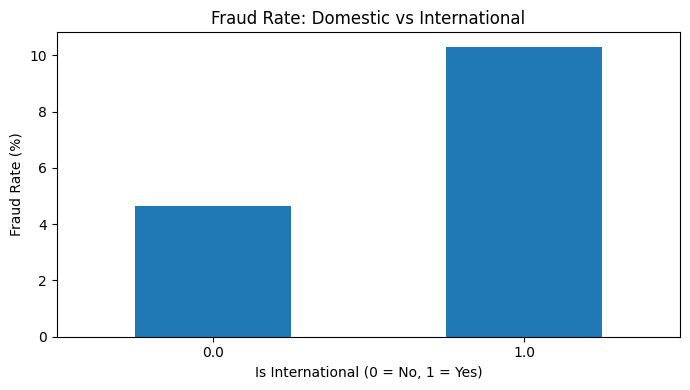

In [22]:

# Step 14: Geographic Analysis

# Country-level fraud analysis
country_analysis = df.groupby("country").agg(
    Total_Transactions=("is_fraud", "size"),
    Fraud_Cases=("is_fraud", "sum"),
    Fraud_Rate=("is_fraud", "mean")
)

country_analysis["Fraud_Rate_Percent"] = (
    country_analysis["Fraud_Rate"] * 100
).round(2)

display(
    country_analysis.sort_values(
        "Fraud_Rate_Percent", ascending=False
    )
)

# International vs domestic transactions
international_analysis = df.groupby("is_international").agg(
    Total_Transactions=("is_fraud", "size"),
    Fraud_Cases=("is_fraud", "sum"),
    Fraud_Rate=("is_fraud", "mean")
)

international_analysis["Fraud_Rate_Percent"] = (
    international_analysis["Fraud_Rate"] * 100
).round(2)

display(international_analysis)

international_analysis["Fraud_Rate_Percent"].plot(
    kind="bar", figsize=(7, 4)
)

plt.title("Fraud Rate: Domestic vs International")
plt.xlabel("Is International (0 = No, 1 = Yes)")
plt.ylabel("Fraud Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()



Analysis of failed_attempts


,count,mean,median
is_fraud,,,
Legitimate,19327,0.35,0.00
Fraudulent,1122,0.86,0.00



Analysis of distance_from_home_km


,count,mean,median
is_fraud,,,
Legitimate,19327,19.87,13.90
Fraudulent,1122,19.65,13.65



Analysis of time_since_last_txn_hrs


...

,count,mean,median
is_fraud,,,
Legitimate,19327,150.06,150.00
Fraudulent,1122,149.45,149.00



Analysis of transaction_freq_monthly


,count,mean,median
is_fraud,,,
Legitimate,19327,20.02,20.00
Fraudulent,1122,19.79,20.00



Analysis of pin_changed_recently


,count,mean,median
is_fraud,,,
Legitimate,19327,0.08,0.00
Fraudulent,1122,0.12,0.00


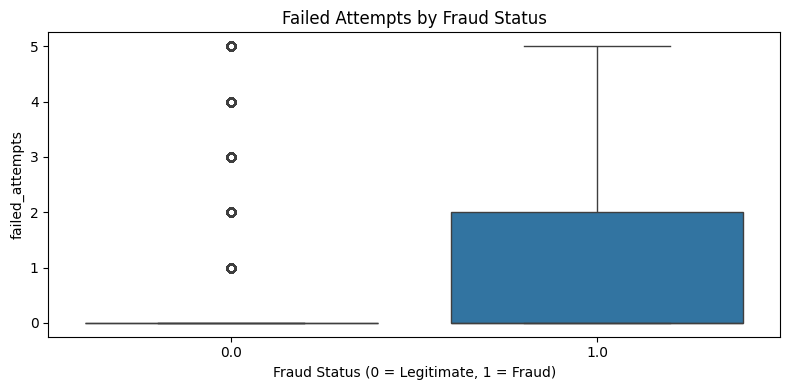

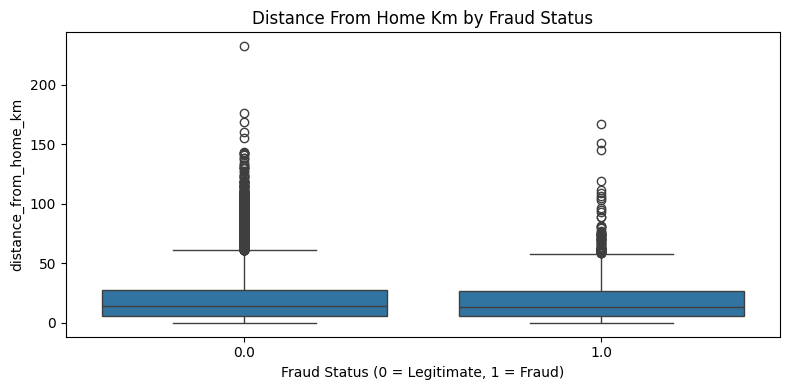

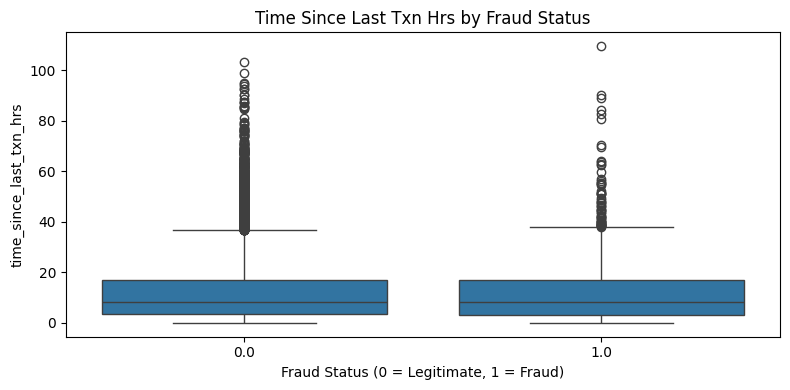

In [23]:

# Step 15: Transaction Behaviour Analysis

behaviour_columns = [
    "failed_attempts",
    "distance_from_home_km",
    "time_since_last_txn_hrs",
    "num_prev_transactions",
    "transaction_freq_monthly",
    "pin_changed_recently"
]

for column in behaviour_columns:
    print(f"\nAnalysis of {column}")

    summary = df.groupby("is_fraud")[column].agg(
        ["count", "mean", "median"]
    )

    summary.index = summary.index.map({
        0: "Legitimate",
        1: "Fraudulent"
    })

    display(summary.round(2))


# Visualize selected behavioural patterns
for column in [
    "failed_attempts",
    "distance_from_home_km",
    "time_since_last_txn_hrs"
]:
    plt.figure(figsize=(8, 4))

    sns.boxplot(
        data=df,
        x="is_fraud",
        y=column
    )

    plt.title(f"{column.replace('_', ' ').title()} by Fraud Status")
    plt.xlabel("Fraud Status (0 = Legitimate, 1 = Fraud)")
    plt.tight_layout()
    plt.show()



customer_age by Fraud Status


,count,mean,median,min,max
is_fraud,,,,,
0.00,19327,41.67,41.00,18,85
1.00,1122,41.07,41.00,18,83



credit_score by Fraud Status


,count,mean,median,min,max
is_fraud,,,,,
0.00,19327,679.73,679.00,384,850
1.00,1122,678.31,679.00,422,850



account_age_years by Fraud Status


,count,mean,median,min,max
is_fraud,,,,,
0.00,19327,4.93,3.50,0.10,30.00
1.00,1122,5.02,3.40,0.10,30.00



account_balance by Fraud Status


,count,mean,median,min,max
is_fraud,,,,,
0.00,19327,"16,592.41","7,977.70",100.00,"500,000.00"
1.00,1122,"17,479.54","8,037.26",186.81,"500,000.00"


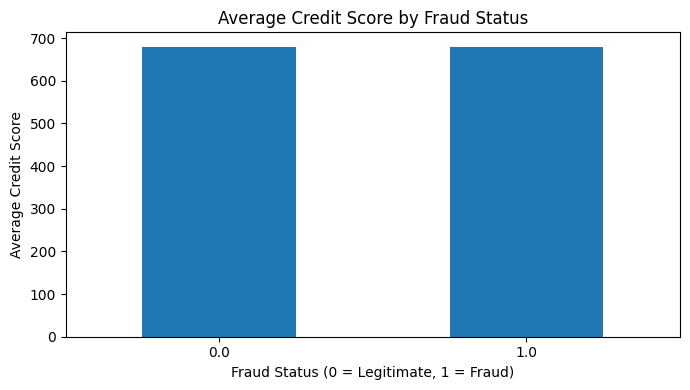

In [24]:

# Step 16: Customer Profile Analysis

customer_columns = [
    "customer_age",
    "credit_score",
    "account_age_years",
    "account_balance"
]

for column in customer_columns:
    print(f"\n{column} by Fraud Status")

    display(
        df.groupby("is_fraud")[column]
        .agg(["count", "mean", "median", "min", "max"])
        .round(2)
    )

# Compare average credit scores
df.groupby("is_fraud")["credit_score"].mean().plot(
    kind="bar", figsize=(7, 4)
)

plt.title("Average Credit Score by Fraud Status")
plt.xlabel("Fraud Status (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Average Credit Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


,Total_Transactions,Fraud_Cases,Fraud_Rate,Fraud_Rate_Percent
Transaction_Month,,,,
2020-01,396,31.00,0.08,7.83
2020-02,344,16.00,0.05,4.65
2020-03,396,20.00,0.05,5.05
2020-04,340,20.00,0.06,5.88
2020-05,316,17.00,0.05,5.38
2020-06,350,19.00,0.05,5.43
2020-07,355,14.00,0.04,3.94
2020-08,369,18.00,0.05,4.88
2020-09,337,11.00,0.03,3.26


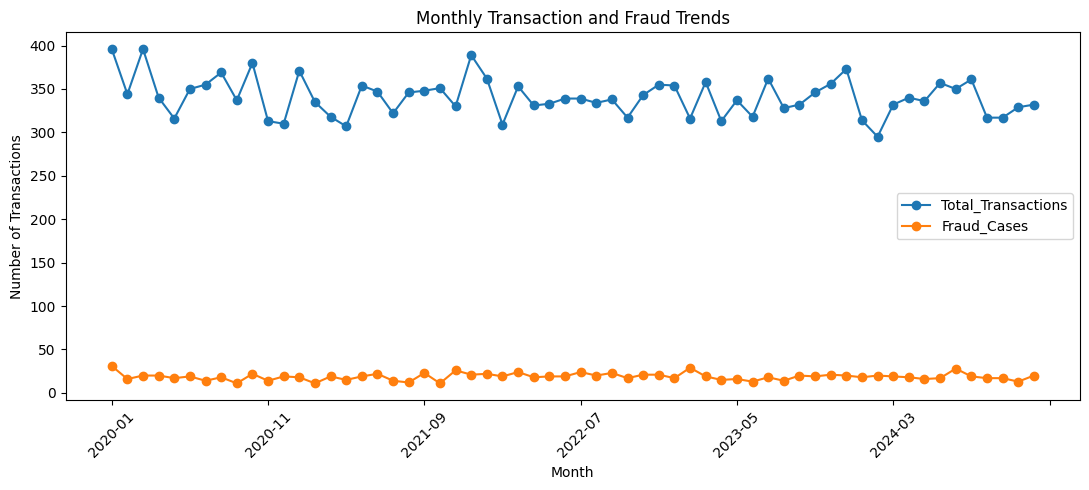

In [25]:

# Step 17: Fraud Trends Over Time

df["transaction_date"] = pd.to_datetime(
    df["transaction_date"], errors="coerce"
)

date_data = df.dropna(subset=["transaction_date"]).copy()

date_data["Transaction_Month"] = (
    date_data["transaction_date"].dt.to_period("M").astype(str)
)

monthly_analysis = date_data.groupby("Transaction_Month").agg(
    Total_Transactions=("is_fraud", "size"),
    Fraud_Cases=("is_fraud", "sum"),
    Fraud_Rate=("is_fraud", "mean")
)

monthly_analysis["Fraud_Rate_Percent"] = (
    monthly_analysis["Fraud_Rate"] * 100
).round(2)

display(monthly_analysis)

monthly_analysis[["Total_Transactions", "Fraud_Cases"]].plot(
    figsize=(11, 5), marker="o"
)

plt.title("Monthly Transaction and Fraud Trends")
plt.xlabel("Month")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [26]:

# Step 18: Summary of Key Findings

total_transactions = len(df)
fraud_cases = int((df["is_fraud"] == 1).sum())
legitimate_cases = int((df["is_fraud"] == 0).sum())

fraud_rate = (
    fraud_cases / total_transactions * 100
    if total_transactions else 0
)

fraud_data = df[df["is_fraud"] == 1].copy()

print("=" * 55)
print("BANK TRANSACTION FRAUD ANALYSIS")
print("=" * 55)

print(f"Total transactions: {total_transactions:,}")
print(f"Fraudulent transactions: {fraud_cases:,}")
print(f"Legitimate transactions: {legitimate_cases:,}")
print(f"Overall fraud rate: {fraud_rate:.2f}%")

print(
    "\nTotal transaction amount labelled fraudulent:",
    f"{fraud_data['transaction_amount'].sum():,.2f}"
)

print(
    "Average fraudulent transaction amount:",
    f"{fraud_data['transaction_amount'].mean():,.2f}"
)

if not fraud_data.empty:
    print(
        "\nMost frequent fraud type:",
        fraud_data["fraud_type"].value_counts().idxmax()
    )

    print(
        "Fraud type with highest total transaction amount:",
        fraud_data.groupby("fraud_type")["transaction_amount"]
        .sum().idxmax()
    )

print("\nAnalysis summary completed.")


BANK TRANSACTION FRAUD ANALYSIS
Total transactions: 20,450
Fraudulent transactions: 1,122
Legitimate transactions: 19,327
Overall fraud rate: 5.49%

Total transaction amount labelled fraudulent: 241,791.66
Average fraudulent transaction amount: 215.50

Most frequent fraud type: Friendly Fraud
Fraud type with highest total transaction amount: Friendly Fraud

Analysis summary completed.
